In [ ]:
import torch
torch.cuda.is_available()

True

In [ ]:
!pip install -q transformers peft accelerate bitsandbytes datasets
# peft: traines small set of additional parameters like LoRA adapters

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 32.8 MB/s eta 0:00:00


In [4]:
#load dataset
import pandas as pd

train_full = pd.read_csv("/kaggle/input/competitions/nppe-dlp-2026-term-1/train.csv")
# train = pd.read_csv("/kaggle/input/competitions/nppe-dlp-2026-term-1/train.csv")
test = pd.read_csv("/kaggle/input/competitions/nppe-dlp-2026-term-1/test.csv")

# train.head()
train_full.head()

,ID,sentence,label,language
0,82,ਇਹ ਫਿਲਮ ਇੱਕ ਬੇਹਤਰੀਨ ਕਹਾਣੀ ਸੁਣਾਉਣ ਦਾ ਸਭ ਤੋਂ ਵਧੀ...,Negative,pa
1,618,"ਇੱਕ ਸਮਗਰੀ ਦੇ ਰੂਪ ਵਿੱਚ, ਕੋਟਿੰਗ ਤੋਂ ਬਿਨਾਂ, ਸਿਰਫ ...",Negative,pa
2,812,"ബ്രിസിലുകൾ കട്ടിയുള്ള പ്ലാസ്റ്റിക് ആണ്, അതിനാൽ...",Negative,ml
3,304,এটি বিআইএস প্রত্যয়িত এবং নিরাপদ বলে দাবি করা হয়।,Positive,bn
4,295,6 mAh બેટરી અને લાંબા સમય સુધી ચાલતી નથી.,Negative,gu


# EDA

/tmp/ipykernel_24/1748802409.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=train_full, x='label', palette='Set2')
/tmp/ipykernel_24/1748802409.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=train_full, y='language', order=order, palette='viridis')
/tmp/ipykernel_24/1748802409.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_full, x='language', y='word_count', order=order, palette='Set3')


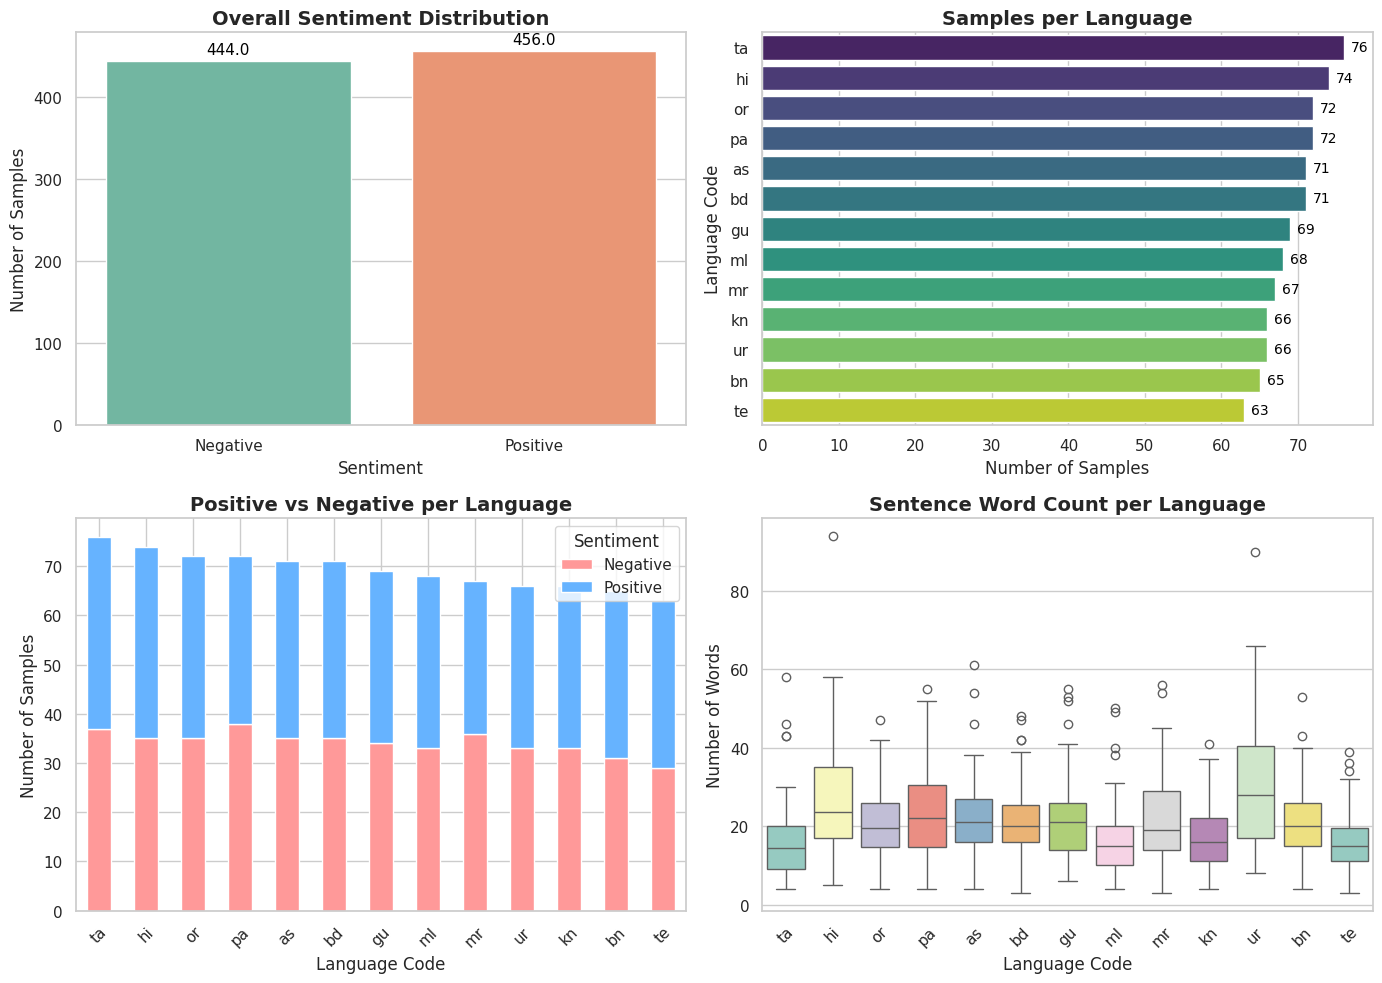


Longest sentence in the dataset has 94 words.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 10)

# ==========================================
# 1. Overall Class Distribution
# ==========================================
plt.subplot(2, 2, 1)
ax = sns.countplot(data=train_full, x='label', palette='Set2')
plt.title("Overall Sentiment Distribution", fontsize=14, fontweight='bold')
plt.xlabel("Sentiment")
plt.ylabel("Number of Samples")
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=11, color='black', xytext=(0, 5), textcoords='offset points')
#If one label is much more frequent than the other, accuracy becomes misleading.

# ==========================================
# 2. Total Samples per Language
# ==========================================
plt.subplot(2, 2, 2)
order = train_full['language'].value_counts().index
ax = sns.countplot(data=train_full, y='language', order=order, palette='viridis')
plt.title("Samples per Language", fontsize=14, fontweight='bold')
plt.xlabel("Number of Samples")
plt.ylabel("Language Code")
for p in ax.patches:
    ax.annotate(f'{int(p.get_width())}', (p.get_width(), p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=10, color='black', xytext=(5, 0), textcoords='offset points')

# ==========================================
# 3. Class Distribution WITHIN Each Language
# ==========================================
plt.subplot(2, 2, 3)
# Group by language and label
lang_label_counts = train_full.groupby(['language', 'label']).size().unstack().fillna(0)
# Sort by total samples
lang_label_counts['Total'] = lang_label_counts.sum(axis=1)
lang_label_counts = lang_label_counts.sort_values(by='Total', ascending=False).drop('Total', axis=1)

lang_label_counts.plot(kind='bar', stacked=True, color=['#ff9999', '#66b3ff'], ax=plt.gca())
plt.title("Positive vs Negative per Language", fontsize=14, fontweight='bold')
plt.xlabel("Language Code")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.legend(title='Sentiment')

# ==========================================
# 4. Sentence Length Distribution (Word Count)
# ==========================================
plt.subplot(2, 2, 4)
# Calculate word count for each sentence
train_full['word_count'] = train_full['sentence'].apply(lambda x: len(str(x).split()))

sns.boxplot(data=train_full, x='language', y='word_count', order=order, palette='Set3')
plt.title("Sentence Word Count per Language", fontsize=14, fontweight='bold')
plt.xlabel("Language Code")
plt.ylabel("Number of Words")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()
#Because tokenization length and truncation depend on input size. If sentences are short, a max length like 256 is safe.

# Print the longest sentence to check max_length
max_words = train_full['word_count'].max()
print(f"\nLongest sentence in the dataset has {max_words} words.")

In [6]:
import pandas as pd

# Calculate word count for each sentence
train_full['word_count'] = train_full['sentence'].apply(lambda x: len(str(x).split()))

print("=== 1. OVERALL CLASS DISTRIBUTION ===")
print(train_full['label'].value_counts().to_string())
print("\n")

print("=== 2. TOTAL SAMPLES PER LANGUAGE ===")
print(train_full['language'].value_counts().to_string())
print("\n")

print("=== 3. POSITIVE VS NEGATIVE PER LANGUAGE ===")
lang_label_counts = train_full.groupby(['language', 'label']).size().unstack(fill_value=0)
lang_label_counts['Total'] = lang_label_counts.sum(axis=1)
lang_label_counts = lang_label_counts.sort_values(by='Total', ascending=False)
print(lang_label_counts.to_string())
print("\n")

print("=== 4. SENTENCE LENGTH (WORD COUNT) STATISTICS ===")
print(f"Max words in a single sentence: {train_full['word_count'].max()}")
print(f"Average words per sentence: {train_full['word_count'].mean():.1f}")
print("--------------------------------------------------")
print("Longest sentences by language:")
print(train_full.groupby('language')['word_count'].max().sort_values(ascending=False).to_string())

=== 1. OVERALL CLASS DISTRIBUTION ===
label
Positive    456
Negative    444


=== 2. TOTAL SAMPLES PER LANGUAGE ===
language
ta    76
hi    74
or    72
pa    72
as    71
bd    71
gu    69
ml    68
mr    67
kn    66
ur    66
bn    65
te    63


=== 3. POSITIVE VS NEGATIVE PER LANGUAGE ===
label     Negative  Positive  Total
language                           
ta              37        39     76
hi              35        39     74
or              35        37     72
pa              38        34     72
as              35        36     71
bd              35        36     71
gu              34        35     69
ml              33        35     68
mr              36        31     67
ur              33        33     66
kn              33        33     66
bn              31        34     65
te              29        34     63


=== 4. SENTENCE LENGTH (WORD COUNT) STATISTICS ===
Max words in a single sentence: 94
Average words per sentence: 21.2
--------------------------------------------------

In [10]:
#convert labels
label2id = {"Negative":0, "Positive":1}
id2label = {0:"Negative", 1:"Positive"}

train_full["label_id"] = train_full["label"].map(label2id)
# train["label_id"] = train["label"].map(label2id)

# Split and concat

In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd

# 1. SPLIT FIRST (This locks away the validation data safely)
train_df, val_df = train_test_split(
    train_full, 
    test_size=0.1, 
    random_state=42, 
    stratify=train_full["label"] #Ensures class proportions are preserved in both splits.
)
# better split : both label and language, because language imbalance also matters in multilingual tasks.

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f"Original Training samples: {len(train_df)}")
print(f"Validation samples: {len(val_df)}")



Original Training samples: 810
Validation samples: 90


In [ ]:
# import pandas as pd

# # 1. SET UP THE GLOBAL ANCHORS USING 100% OF THE DATA
# hi_pos = train_full[(train_full['language'] == 'hi') & (train_full['label'] == 'Positive')].iloc[0]
# ta_pos = train_full[(train_full['language'] == 'ta') & (train_full['label'] == 'Positive')].iloc[0]
# default_neg = train_full[train_full['label'] == 'Negative'].iloc[0]

# dravidian_langs = ['ta', 'te', 'kn', 'ml']

# # 2. SURGICAL OVERSAMPLING FOR THE FINAL RUN
# extreme_weak_lang = ['bd']                 # Bodo gets the 8x Nuke
# moderate_weak_langs = ['ml', 'as', 'ur']   # These get a 4x Push
# #low score for these lang
 
# bodo_df = train_full[train_full['language'].isin(extreme_weak_lang)]
# mod_df = train_full[train_full['language'].isin(moderate_weak_langs)]

# amplified_df = pd.concat(
#     [bodo_df] * 8 + 
#     [mod_df] * 4
# )

# # Merge back into the FULL dataset
# final_train = pd.concat([train_full, amplified_df]).sample(frac=1, random_state=42).reset_index(drop=True)
# print(f"Final Surgical Training Set Size: {len(final_train)} samples")



Final Surgical Training Set Size: 2288 samples


In [13]:
# import pandas as pd

# # Calculate word count for each sentence in the new amplified dataset
# final_train['word_count'] = final_train['sentence'].apply(lambda x: len(str(x).split()))

# print("=== 1. OVERALL CLASS DISTRIBUTION (FINAL TRAIN) ===")
# print(final_train['label'].value_counts().to_string())
# print("\n")

# print("=== 2. TOTAL SAMPLES PER LANGUAGE (FINAL TRAIN) ===")
# print(final_train['language'].value_counts().to_string())
# print("\n")

# print("=== 3. POSITIVE VS NEGATIVE PER LANGUAGE (FINAL TRAIN) ===")
# lang_label_counts = final_train.groupby(['language', 'label']).size().unstack(fill_value=0)
# lang_label_counts['Total'] = lang_label_counts.sum(axis=1)
# lang_label_couAnts = lang_label_counts.sort_values(by='Total', ascending=False)
# print(lang_label_counts.to_string())
# print("\n")

# print("=== 4. SENTENCE LENGTH STATISTICS (FINAL TRAIN) ===")
# print(f"Max words in a single sentence: {final_train['word_count'].max()}")
# print(f"Average words per sentence: {final_train['word_count'].mean():.1f}")
# print("--------------------------------------------------")
# print("Longest sentences by language:")
# print(final_train.groupby('language')['word_count'].max().sort_values(ascending=False).to_string())

# HF model

In [ ]:
!pip install -q huggingface_hub
import os
from huggingface_hub import login

# Use an environment variable for safety; do not hardcode tokens in notebooks.
hf_token = os.getenv("HF_TOKEN")
if not hf_token:
    raise ValueError("Set HF_TOKEN in your environment before running login().")

login(token=hf_token)


In [ ]:
import torch
torch.cuda.empty_cache()

In [ ]:
# quant: lesser precision (memory)
# lora: lesser trainable params
# QLoRA : for training large models on a single GPU. 
# Use LoRA : more than enough VRAM and need faster training

# Qlora:
# freezing a pre-trained base model,
# quantizing it to 4-bit precision (NF4), 
# add small, trainable adapter layers (LoRA) 
# that are updated during training

# Lora:
# freezes pre-trained weights 
# adds tiny, trainable "adapter" matrices (low-rank matrices)
# to specific layers.

In [ ]:
from transformers import BitsAndBytesConfig 

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16
)

In [ ]:
#load gemma model
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import prepare_model_for_kbit_training, LoraConfig, get_peft_model

model_name = "google/gemma-3-1b-it" #instruction tuned

tokenizer = AutoTokenizer.from_pretrained(model_name) #raw text to token ids

model = AutoModelForCausalLM.from_pretrained( # next token gen
    model_name,
    quantization_config=quant_config,
    torch_dtype=torch.float16,
    device_map="cuda:0"
)
model.gradient_checkpointing_enable() #recomputes activativation during back prop: doesnot store: saves memory
model = prepare_model_for_kbit_training(model)

config.json:   0%|          | 0.00/899 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/2.00G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

In [ ]:
from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=128, #rank
    lora_alpha=256,
    target_modules=[ #sublayers
        "q_proj", "k_proj", "v_proj", "o_proj", 
        "gate_proj", "up_proj", "down_proj"
    ],
    modules_to_save=["embed_tokens", "lm_head"], 
    lora_dropout=0.05, 
    bias="none",
    task_type="CAUSAL_LM"
)

# 5. Apply LoRA
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

/usr/local/lib/python3.12/dist-packages/peft/tuners/tuners_utils.py:1225: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. Check the discussion here: https://github.com/huggingface/peft/issues/2777
  warnings.warn(msg)


trainable params: 708,345,856 || all params: 1,708,231,808 || trainable%: 41.4666


In [ ]:
import pandas as pd

# ==========================================
# 1. SET UP THE GLOBAL ANCHORS (100% Data) 
# ==========================================
hi_pos = train_full[(train_full['language'] == 'hi') & (train_full['label'] == 'Positive')].iloc[0]
ta_pos = train_full[(train_full['language'] == 'ta') & (train_full['label'] == 'Positive')].iloc[0]
default_neg = train_full[train_full['label'] == 'Negative'].iloc[0]

dravidian_langs = ['ta', 'te', 'kn', 'ml']

# ==========================================
# 2. DEFINE THE PROMPT BUILDER FIRST
# ==========================================
def build_family_anchored_prompt(row, source_df):
    lang = row['language']
    
    # Dynamically select the correct anchor based on language family
    anchor_pos = ta_pos if lang in dravidian_langs else hi_pos
    
    # Dynamically grab the NEGATIVE example from the target language
    lang_df = source_df[(source_df['language'] == lang) & (source_df.index != row.name)]
    neg_df = lang_df[lang_df['label'] == 'Negative']
    target_neg = neg_df.iloc[0] if not neg_df.empty else default_neg
    
    messages = [
        # Use the family-specific anchor!
        {"role": "user", "content": f"You are a multilingual sentiment classifier. Analyze the sentiment of the following sentence and answer STRICTLY with the word 'Positive' or 'Negative'.\n\nLanguage: {anchor_pos['language']}\nSentence: {anchor_pos['sentence']}"},
        {"role": "model", "content": "Positive"},
        # Introduce the target language negative example
        {"role": "user", "content": f"Language: {target_neg['language']}\nSentence: {target_neg['sentence']}"},
        {"role": "model", "content": "Negative"},
        # Ask for the actual prediction
        {"role": "user", "content": f"Language: {row['language']}\nSentence: {row['sentence']}"}
    ]
    
    if 'label' in row:
        messages.append({"role": "model", "content": row['label']})
        
    return tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=('label' not in row)
    )

# ==========================================
# 3. THE ALIEN SCRIPT AMPLIFICATION
# ==========================================
# These languages are completely foreign to base Gemma. 
alien_langs = ['bd', 'or', 'as', 'ml'] 
alien_df = train_full[train_full['language'].isin(alien_langs)]

# We amplify them 10x so Gemma is forced to dedicate LoRA weights to their alphabets
amplified_df = pd.concat([alien_df] * 10)

# Merge back into the FULL dataset 
final_train = pd.concat([train_full, amplified_df]).sample(frac=1, random_state=42).reset_index(drop=True)
print(f"Final Amplified Training Set Size: {len(final_train)} samples")

# ==========================================
# 4. APPLY THE PROMPTS
# ==========================================
final_train["prompt"] = final_train.apply(lambda row: build_family_anchored_prompt(row, final_train), axis=1)

Final Amplified Training Set Size: 3720 samples


In [ ]:
#tokenize data
from datasets import Dataset

dataset = Dataset.from_pandas(final_train) #train_df or train_full

# Some causal LMs do not have a pad token by default. So the EOS token is reused.
tokenizer.pad_token = tokenizer.eos_token

def tokenize(example):
    tokens = tokenizer(
        example["prompt"],
        truncation=True,
        padding="max_length",
        max_length=256    #but max senten length was 96 words
    )
    
    #causal language modeling trains the model to predict the next token in the same sequence
    tokens["labels"] = tokens["input_ids"].copy() 
    #ignore these -100 pos in los calculation
    tokens["labels"] = [
        -100 if token == tokenizer.pad_token_id else token 
        for token in tokens["labels"]
    ]
    return tokens
    
dataset_tokenized = dataset.map(tokenize)

Map:   0%|          | 0/3720 [00:00<?, ? examples/s]

In [ ]:
# Keep only model-ready columns after tokenization.
dataset = dataset_tokenized.remove_columns(["sentence", "language", "label", "prompt", "ID"])

# input_ids
# attention_mask
# labels

In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./results",
    per_device_train_batch_size=4,        # each forward pass sees 4 examples
    gradient_accumulation_steps=4,        # Accumulate gradients over 4 steps before optimizer update : so effective batch size = 4*4
    gradient_checkpointing=True,          #  Memory saving trick
    num_train_epochs=3,                   # full training set is seen 3 times
    learning_rate=1e-4,
    lr_scheduler_type="cosine",           # gradually decays in cosine pattern
    warmup_ratio=0.1,                     # 10% training steps slowly increase learning rate
    logging_steps=10,
    save_strategy="epoch",                #Save checkpoint after each epoch.
    save_total_limit=1,                   # only latest checkpoint(s) to save disk
    dataloader_num_workers=2,             # 2 CPU workers for data loading
    fp16=True,                            # computation
    bf16=False, 
    optim="paged_adamw_8bit",             # Memory-efficient AdamW optimizer.
    weight_decay=0.01,
)

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [ ]:
import os

output_dir = "./results" 

if os.path.exists(output_dir):
    folders = [f for f in os.listdir(output_dir) if f.startswith("checkpoint")]
    # Sort them by step number
    folders.sort(key=lambda x: int(x.split("-")[-1]))
    print("Found these saved checkpoints:")
    for folder in folders:
        print(folder)
else:
    print("Directory not found.")

Directory not found.


In [ ]:
from transformers import Trainer

#training loop, batching, optimization, checkpointing, logging
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset,
)

print("Starting training...")
trainer.train()

Starting training...


Step,Training Loss
10,6.683295
20,3.833887
30,2.077085
40,1.217131
50,1.040820
60,0.845611
70,0.723300
80,0.667358
90,0.655378
100,0.569729


TrainOutput(global_step=699, training_loss=0.38109629817616103, metrics={'train_runtime': 4110.7232, 'train_samples_per_second': 2.715, 'train_steps_per_second': 0.17, 'total_flos': 1.892882331205632e+16, 'train_loss': 0.38109629817616103, 'epoch': 3.0})

In [26]:
# from peft import PeftModel

# # This overwrites your base model with your trained Epoch 3 weights!
# model = PeftModel.from_pretrained(model, "./results/checkpoint-381")

# print("Successfully loaded Epoch 3 weights! Ready to predict.")

# Predict

In [ ]:
# hi_pos = train_full[(train_full['language'] == 'hi') & (train_full['label'] == 'Positive')].iloc[0]
# ta_pos = train_full[(train_full['language'] == 'ta') & (train_full['label'] == 'Positive')].iloc[0]
# default_neg = train_full[train_full['label'] == 'Negative'].iloc[0]

# dravidian_langs = ['ta', 'te', 'kn', 'ml']

def predict(sentence, language, source_df):
    anchor_pos = ta_pos if language in dravidian_langs else hi_pos
    lang_df = source_df[source_df['language'] == language]
    neg_df = lang_df[lang_df['label'] == 'Negative']
    target_neg = neg_df.iloc[0] if not neg_df.empty else default_neg

    messages = [
        {"role": "user", "content": f"You are a multilingual sentiment classifier. Analyze the sentiment of the following sentence and answer STRICTLY with the word 'Positive' or 'Negative'.\n\nLanguage: {anchor_pos['language']}\nSentence: {anchor_pos['sentence']}"},
        {"role": "model", "content": "Positive"},
        
        {"role": "user", "content": f"Language: {target_neg['language']}\nSentence: {target_neg['sentence']}"},
        {"role": "model", "content": "Negative"},

        {"role": "user", "content": f"Language: {language}\nSentence: {sentence}"}
    ]
    
    # Sentence: I love this movie
    # Answer:

    # To
    
    # <start_of_turn>user
    # Sentence: I love this movie
    # Answer:
    # <end_of_turn>
    # <start_of_turn>model

    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True) #
    inputs = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(model.device)
    
    # Force greedy decoding ->determnistic outcome
    output = model.generate(
        **inputs, 
        max_new_tokens=5, 
        do_sample=False,
        temperature=None,
        top_p=None,
        pad_token_id=tokenizer.eos_token_id
    )
    
    # Slice off the prompt and decode only the generated answer
    input_length = inputs["input_ids"].shape[1]
    generated_tokens = output[0][input_length:]
    text = tokenizer.decode(generated_tokens, skip_special_tokens=True).strip()

    # Convert the semantic word back to the 1/0 integer required for scoring
    if "Positive" in text:
        return 1
    else:
        return 0

validation

In [ ]:
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

# Lists to hold our results
val_preds = []
# Pull the 1s and 0s, NOT the strings
val_actuals = val_df["label_id"].tolist() 

print("Running evaluation on validation set...")

# Iterate through the validation set
for _, row in tqdm(val_df.iterrows(), total=len(val_df)):
# Inside your validation loop:
    pred = predict(row["sentence"], row["language"], train_full)    
    val_preds.append(pred)

# Calculate Macro F1-Score
val_f1 = f1_score(val_actuals, val_preds, average="macro")

print(f"\nLocal Validation Macro F1-Score: {val_f1:.4f}")

Running evaluation on validation set...


  0%|          | 0/90 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
Caching is incompatible with gradient checkpointing in Gemma3DecoderLayer. Setting `past_key_values=None`.



Local Validation Macro F1-Score: 0.9778


In [ ]:
# Add your predictions directly to the validation dataframe
val_df["prediction"] = val_preds

print("--- F1 Score by Language ---")

# Loop through each unique language
for lang in val_df["language"].unique():
    # Filter for only the current language
    lang_df = val_df[val_df["language"] == lang]
    
    # Calculate the Macro F1 for just this language
    lang_f1 = f1_score(lang_df["label_id"], lang_df["prediction"], average="macro")
    
    print(f"Language: {lang.upper():<3} | F1-Score: {lang_f1:.4f} | Samples: {len(lang_df)}")

from sklearn.metrics import classification_report

print("--- DEEP DIAGNOSTIC BY LANGUAGE ---")
for lang in val_df["language"].unique():
    lang_df = val_df[val_df["language"] == lang]
    
    print(f"\nLanguage: {lang.upper()}")
    # This will show you exactly if the model is ignoring Positives or Negatives!
    print(classification_report(
        lang_df["label_id"], 
        lang_df["prediction"], 
        target_names=["Negative", "Positive"],
        zero_division=0
    ))

--- F1 Score by Language ---
Language: PA  | F1-Score: 1.0000 | Samples: 10
Language: BD  | F1-Score: 0.7879 | Samples: 7
Language: MR  | F1-Score: 1.0000 | Samples: 10
Language: BN  | F1-Score: 1.0000 | Samples: 5
Language: GU  | F1-Score: 1.0000 | Samples: 6
Language: HI  | F1-Score: 1.0000 | Samples: 9
Language: KN  | F1-Score: 1.0000 | Samples: 10
Language: TA  | F1-Score: 1.0000 | Samples: 7
Language: UR  | F1-Score: 1.0000 | Samples: 6
Language: TE  | F1-Score: 1.0000 | Samples: 7
Language: ML  | F1-Score: 1.0000 | Samples: 4
Language: OR  | F1-Score: 0.6667 | Samples: 3
Language: AS  | F1-Score: 1.0000 | Samples: 6
--- DEEP DIAGNOSTIC BY LANGUAGE ---

Language: PA
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00         6
    Positive       1.00      1.00      1.00         4

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00     

Inference

In [30]:
preds = []

print("Running inference on hidden test set...")
for _, row in test.iterrows():
    # p is already returning 1 or 0 from our predict function
    p = predict(row["sentence"], row["language"], train_full)
    
    # Append the integer directly (no brackets, no dictionary mapping)
    preds.append(p)

# Generate the final submission dataframe
submission = pd.DataFrame({
    "ID": test["ID"],
    "label": preds
})

submission.to_csv("submission.csv", index=False)
print("Submission saved successfully!")
print(submission.head())
# should only have ID, lable(int)

Running inference on hidden test set...
Submission saved successfully!
    ID  label
0  550      1
1  397      1
2  757      1
3  407      0
4  294      0
